# **ENGE707 Assignment 2**


# Task 1: Dataset Exploration and Understanding

### Setup

In [7]:
# --- Imports ---------------------------------------------------------------
from pathlib import Path            # object-oriented file paths; '/' joins folders and works on Windows and Linux
import numpy as np                  # numerical arrays (pixel maths)
import pandas as pd                 # tables (DataFrames) for labels and per-image measurements
import matplotlib.pyplot as plt     # plotting
from PIL import Image               # Pillow: opens and decodes image files

# --- Paths -----------------------------------------------------------------
# The dataset sits one folder ABOVE this repo ('..' = parent folder), so it is never committed to git.
DATA_DIR = Path('..') / 'enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch'

# Dictionary mapping each split name to its image folder, so later code can loop over both
# with `for split, folder in IMG_DIR.items()`. The Kaggle zip nests each folder twice (train/train).
IMG_DIR = {'train': DATA_DIR / 'train' / 'train',
           'test':  DATA_DIR / 'test' / 'test'}

# Folder for saved figures. parents=True creates 'outputs' too if missing;
# exist_ok=True stops it erroring when the folder already exists (re-running the cell).
FIG_DIR = Path('outputs') / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Fixed random seed: every random sample in the notebook picks the same images each run (reproducibility).
SEED = 42

In [8]:
import hashlib, io                                   # hashlib: md5 hashes; io: treat raw bytes like a file
from concurrent.futures import ThreadPoolExecutor    # run the measuring function on several images at once
import imagehash                                     # perceptual hashing (finds visually identical images)
from scipy import ndimage                            # image filters - used for the Laplacian (edge detector)
from tqdm.auto import tqdm                           # progress bar that renders nicely in Jupyter

STATS_CSV    = Path('outputs') / 'image_stats.csv'   # where the measurements are cached
MEASURE_SIZE = 128   # brightness/contrast/sharpness are measured after resizing every image to 128x128,
                     # otherwise a big image and a small image of the same scene would score differently

def measure(path):
    """Open one image file and return a dict of measurements (one row of the final table)."""
    row = {'image_id': path.stem}                    # .stem = file name without extension: '00001.jpg' -> '00001'
    try:
        raw = path.read_bytes()                      # read the whole file once as raw bytes
        row['file_bytes'] = len(raw)                 # file size on disk (bytes)
        row['md5'] = hashlib.md5(raw).hexdigest()    # md5 = fingerprint of the exact bytes:
                                                     # two files with the same md5 are byte-for-byte identical

        # Decode the image from the bytes already in memory (avoids reading the file a second time)
        with Image.open(io.BytesIO(raw)) as im:
            row.update(width=im.width, height=im.height, mode=im.mode)   # mode: 'RGB' colour, 'L' greyscale, ...
            im.load()                                # forces a FULL decode - a truncated/corrupt JPEG raises an error here
            rgb = im.convert('RGB')                  # make every image 3-channel so all are measured the same way

        # Resize to a common size, convert to a float array of shape (128, 128, 3)
        arr  = np.asarray(rgb.resize((MEASURE_SIZE, MEASURE_SIZE)), dtype=np.float32)
        grey = arr.mean(axis=2)                      # average R,G,B -> one greyscale value per pixel, shape (128, 128)

        row.update(
            # Greyscale check: if each pixel's R,G,B are all within ~2 levels of their average,
            # the image has no real colour, even if it is stored as RGB
            grey=bool(np.abs(arr - grey[..., None]).mean() < 2.0),
            brightness=float(grey.mean()),           # average pixel intensity: 0 = black, 255 = white
            contrast=float(grey.std()),              # spread of intensities: low = flat / washed out
            # Laplacian = second-derivative filter that responds to edges. A sharp image has strong edges
            # (large positive and negative responses -> high variance); a blurry one has weak edges (low variance).
            sharpness=float(ndimage.laplace(grey).var()),
            # Perceptual hash: a 64-bit summary of the image's overall structure. Unlike md5, it stays the
            # same if the image is re-saved, re-compressed or resized, so it catches visual duplicates.
            phash=str(imagehash.phash(rgb)),
            error='',                                # empty string = decoded successfully
        )
    except Exception as e:
        row['error'] = repr(e)                       # record WHY it failed instead of crashing the whole scan
    return row

# --- Run the scan once, then reuse the saved CSV ----------------------------
if STATS_CSV.exists():
    print(f'using cached {STATS_CSV} (delete it to re-measure)')
else:
    frames = []                                      # one DataFrame per split, joined at the end
    for split, folder in IMG_DIR.items():
        files = sorted(folder.glob('*'))             # every file in the folder, in a fixed (sorted) order
        # 8 worker threads: while one thread waits on the disk, others decode/measure.
        # Threads (not processes) because multiprocessing doesn't work from a notebook on Windows.
        with ThreadPoolExecutor(8) as ex:
            rows = list(tqdm(ex.map(measure, files), total=len(files), desc=split))   # map applies measure() to every file
        frames.append(pd.DataFrame(rows).assign(split=split))   # list of dicts -> table; add a 'split' column

    df = pd.concat(frames, ignore_index=True)        # stack train + test into one table

    # Attach class labels. dtype=str keeps leading zeros ('00001' instead of 1) so IDs match file names.
    labels = pd.read_csv(DATA_DIR / 'train_labels.csv', dtype={'image_id': str})
    df = df.merge(labels, on='image_id', how='left') # left join: keep every image, add 'class' where an ID matches

    # Test files reuse the same ID numbers as train (00001 exists in both), so the merge above would wrongly
    # copy TRAIN labels onto TEST rows. Blank them: test images have no labels.
    df.loc[df['split'] == 'test', 'class'] = np.nan

    df.to_csv(STATS_CSV, index=False)                # cache so this slow step only ever runs once
    print(f'wrote {STATS_CSV}: {len(df)} rows, {(df["error"] != "").sum()} unreadable')

using cached outputs\image_stats.csv (delete it to re-measure)


In [9]:
# Load the cached measurements. image_id as str keeps leading zeros.
stats = pd.read_csv(STATS_CSV, dtype={'image_id': str, 'class': str})

# Saving to CSV turns empty strings into blank cells, which pandas reads back as NaN - restore them
stats['error'] = stats['error'].fillna('')                 # '' = image decoded fine
stats['grey']  = stats['grey'].fillna(False).astype(bool)  # unreadable images have no value -> treat as False

# Derived columns used later
stats['min_side'] = stats[['width', 'height']].min(axis=1)  # shorter side in pixels (row-wise min)
stats['aspect']   = stats['width'] / stats['height']        # >1 = wider than tall, <1 = taller than wide

# Separate tables for each split; .copy() so later changes to one don't affect `stats`
train = stats[stats.split == 'train'].copy()
test  = stats[stats.split == 'test'].copy()

# Class names in alphabetical order (dropna skips test rows, which have no class)
classes = sorted(train['class'].dropna().unique())
print(f'train rows: {len(train)}   test rows: {len(test)}   classes: {classes}')


def grid(df, title_fn, n_cols=8, size=1.7, fname=None, suptitle=None):
    """Display the images listed in `df` as a grid.
    title_fn: function that takes one row and returns its caption, e.g. lambda r: r['class']
    fname:    if given, also save the figure to outputs/figures/<fname>"""
    n = len(df)
    rows = max(1, int(np.ceil(n / n_cols)))                  # rows needed, rounded up
    fig, axes = plt.subplots(rows, n_cols, figsize=(n_cols * size, rows * (size + .35)), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')                                       # hide axes/ticks on every cell (and blank leftovers)
    for ax, (_, r) in zip(axes.flat, df.iterrows()):         # pair each subplot with one image row
        try:
            ax.imshow(Image.open(IMG_DIR[r.split] / f'{r.image_id}.jpg').convert('RGB'))
        except OSError:                                      # unreadable file -> leave that cell blank
            pass
        ax.set_title(title_fn(r), fontsize=7)
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)                  # overall title above the grid
    plt.tight_layout()                                       # stop titles/images overlapping
    if fname:
        plt.savefig(FIG_DIR / fname, dpi=150)                # dpi=150 = sharp enough for the report
    plt.show()

train rows: 63660   test rows: 29443   classes: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']


### **1. Structure of Data**

In [10]:
# Load the two CSV files supplied by Kaggle
labels = pd.read_csv(DATA_DIR / 'train_labels.csv', dtype={'image_id': str})   # image_id -> class
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')                       # format Kaggle expects

# ---- 1. Folders and files --------------------------------------------------
print('FOLDERS')
for split, folder in IMG_DIR.items():
    files = list(folder.iterdir())                                   # everything in the folder
    exts  = pd.Series([f.suffix.lower() for f in files]).value_counts().to_dict()   # count by extension (.jpg, ...)
    total_mb = sum(f.stat().st_size for f in files) / 1e6           # add up file sizes, bytes -> MB
    print(f'  {split:5s}: {len(files):6d} files | extensions {exts} | total size {total_mb:.1f} MB')


FOLDERS
  train:  63660 files | extensions {'.jpg': 63660} | total size 691.7 MB
  test :  29443 files | extensions {'.jpg': 29443} | total size 322.2 MB


In [7]:
# ---- 2. Label and submission files ---------------------------------------
print('\nCSV FILES')
print(f'  train_labels.csv     : {labels.shape[0]} rows, columns {list(labels.columns)}')
print(f'  sample_submission.csv: {sample.shape[0]} rows, columns {list(sample.columns)}')
display(labels.head(5))                                              # first 5 rows as a table


CSV FILES
  train_labels.csv     : 63660 rows, columns ['image_id', 'class']
  sample_submission.csv: 29443 rows, columns ['image_id', 'class']


,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace
3,00004,DogNose
4,00005,DogNose


In [8]:
# ---- 3. Consistency checks between files and labels ----------------------
train_ids = set(p.stem for p in IMG_DIR['train'].iterdir())         # IDs of the image files actually present
print('CONSISTENCY')
print(f'  duplicate IDs in train_labels.csv : {labels.image_id.duplicated().sum()}')         # same ID listed twice?
print(f'  labels with no image file         : {len(set(labels.image_id) - train_ids)}')      # set difference
print(f'  image files with no label         : {len(train_ids - set(labels.image_id))}')
# sample_submission stores IDs as plain integers (1, 2, ...), so convert the zero-padded file IDs to int to compare
print(f'  test IDs match sample_submission  : {set(test.image_id.astype(int)) == set(sample.image_id)}')
print(f'  train ID range: {labels.image_id.min()}-{labels.image_id.max()} | '
      f'test ID range: {test.image_id.min()}-{test.image_id.max()}')

CONSISTENCY
  duplicate IDs in train_labels.csv : 0
  labels with no image file         : 0
  image files with no label         : 0
  test IDs match sample_submission  : True
  train ID range: 00001-63660 | test ID range: 00001-29443


In [9]:
# ---- 4. Image properties: summary statistics, train vs test --------------
# One summary table of image properties, train vs test
summary = stats.groupby('split').agg(
    images        =('image_id',   'count'),
    colour_modes  =('mode',       lambda m: ', '.join(m.unique())),   # e.g. 'RGB'
    median_width  =('width',      'median'),
    median_height =('height',     'median'),
    min_short_side=('min_side',   'min'),
    max_short_side=('min_side',   'max'),
    median_file_kb=('file_bytes', lambda b: round(b.median() / 1000, 1)),
    mean_brightness=('brightness', lambda b: round(b.mean(), 1)),
    no_colour     =('grey',       'sum'),                             # True counts as 1
    unreadable    =('error',      lambda e: (e != '').sum()),         # empty error = decoded fine
)
summary.T      # .T flips it so each property is a row and train/test are columns


split,test,train
images,29443,63660
colour_modes,RGB,RGB
median_width,82.0,84.0
median_height,80.0,80.0
min_short_side,8,4
max_short_side,1832,2219
median_file_kb,4.2,4.3
mean_brightness,110.4,110.3
no_colour,1179,2610
unreadable,0,0


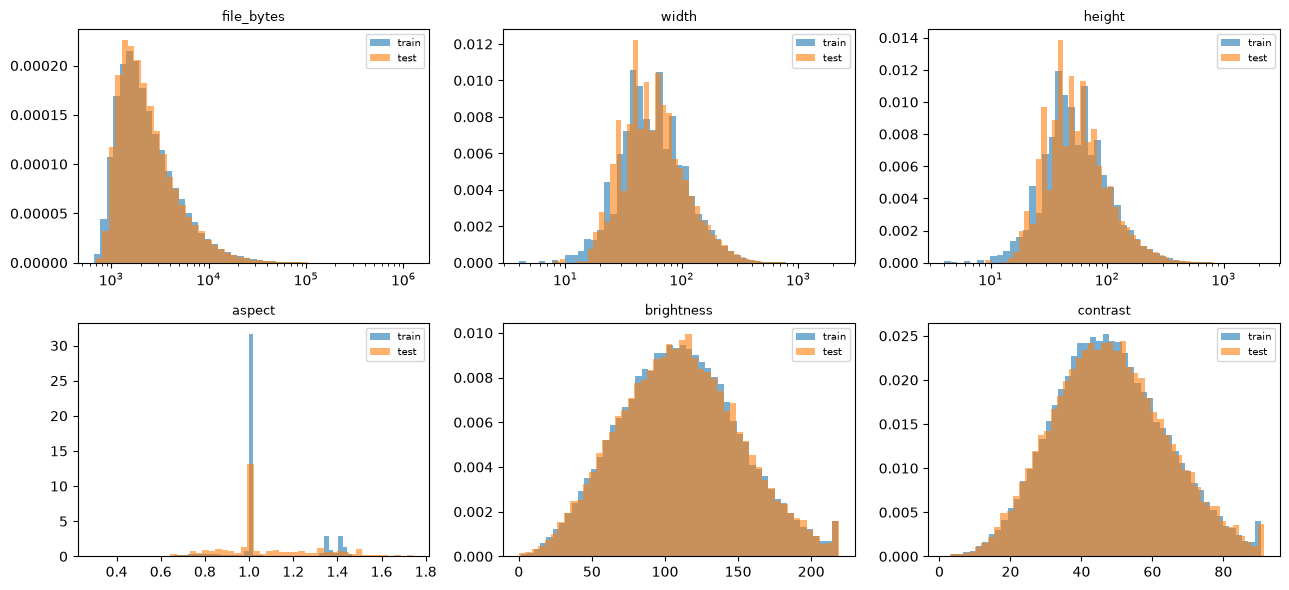

In [10]:
# ---- 5. Distributions, train vs test -------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(13, 6))                    # 6 small plots in a 2x3 grid
for ax, col in zip(axes.flat, ['file_bytes', 'width', 'height', 'aspect', 'brightness', 'contrast']):
    for s, d in (('train', train), ('test', test)):                 # overlay train and test on the same axes
        v = d[col].dropna()                                          # skip unreadable images (no value)
        if col in ('file_bytes', 'width', 'height'):
            # These span tens to hundreds of pixels / thousands of bytes, so use log-spaced bins + log axis
            ax.hist(v, bins=np.logspace(np.log10(v.min()), np.log10(v.max()), 50), alpha=.6, density=True, label=s)
            ax.set_xscale('log')
        else:
            # Clip the top 0.5% so a few extreme values don't squash the rest of the histogram
            ax.hist(v.clip(upper=v.quantile(.995)), bins=50, alpha=.6, density=True, label=s)
    # density=True scales each histogram to area 1, so train (63k) and test (29k) are comparable despite different sizes
    ax.set_title(col, fontsize=9)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIG_DIR / 'structure_overview.png', dpi=150)
plt.show()

### **2.Number of Images in Each Class**

,images,percent
class,,
CatEye,13884,21.81
CatFace,6942,10.90
CatMouth,6942,10.90
CatNose,6942,10.90
DogEye,11580,18.19
DogFace,5790,9.10
DogMouth,5790,9.10
DogNose,5790,9.10


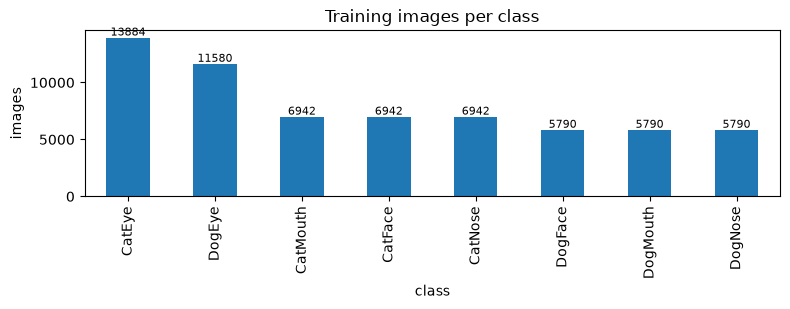

In [11]:
# Count how many training images belong to each class.
# value_counts() counts each unique label; reindex(classes) puts them in alphabetical order
# (instead of largest-first) so the table matches the class list.
counts = train['class'].value_counts().reindex(classes)

# Show as a table with a percentage column.
# assign() adds a new column; the lambda receives the table and computes each class's share of the total.
display(counts.to_frame('images')
              .assign(percent=lambda d: (100 * d.images / d.images.sum()).round(2)))

# Bar chart, sorted largest to smallest so differences are easy to see
ax = counts.sort_values(ascending=False).plot.bar(figsize=(8, 3.2), color='tab:blue')
ax.bar_label(ax.containers[0], fontsize=8)        # write each bar's count on top of it
ax.set_ylabel('images')
ax.set_title('Training images per class')
plt.tight_layout()
plt.savefig(FIG_DIR / 'class_counts.png', dpi=150)  # saved for the report
plt.show()

### **3. Balanced or Imbalanced**

In [12]:
# Split each class name into its two parts so they can be analysed separately:
# 'CatEye' -> species 'Cat' (first 3 characters) and part 'Eye' (everything after).
t = train.assign(species=train['class'].str[:3],
                 part=train['class'].str[3:])

# Imbalance ratio: largest class divided by smallest class. 1.0 would be perfectly balanced.
# idxmax()/idxmin() return the NAME of the largest/smallest class.
print(f'largest / smallest class ratio: {counts.max() / counts.min():.2f}  '
      f'({counts.idxmax()} {counts.max()} vs {counts.idxmin()} {counts.min()})')

# Cross-tabulation: rows = species, columns = body part, cells = image counts.
# margins=True adds row and column totals ('All').
display(pd.crosstab(t['species'], t['part'], margins=True))

# Share of the dataset by species and by part (normalize=True gives fractions instead of counts)
print('by species:'); display(t['species'].value_counts(normalize=True).round(3))
print('by part:');    display(t['part'].value_counts(normalize=True).round(3))

# Each face has two eyes, so the Eye counts are halved to compare them on a "per animal" basis
# against the other parts. .astype(float) because halving can give non-integers.
per_animal = pd.crosstab(t['species'], t['part']).astype(float)
per_animal['Eye'] /= 2
print('crops per part with eyes halved:'); display(per_animal)

largest / smallest class ratio: 2.40  (CatEye 13884 vs DogFace 5790)


part,Eye,Face,Mouth,Nose,All
species,,,,,
Cat,13884,6942,6942,6942,34710
Dog,11580,5790,5790,5790,28950
All,25464,12732,12732,12732,63660


by species:


species
Cat    0.545
Dog    0.455
Name: proportion, dtype: float64

by part:


part
Eye      0.4
Mouth    0.2
Face     0.2
Nose     0.2
Name: proportion, dtype: float64

crops per part with eyes halved:


part,Eye,Face,Mouth,Nose
species,,,,
Cat,6942.0,6942.0,6942.0,6942.0
Dog,5790.0,5790.0,5790.0,5790.0


### **4. Representative Sample Images**

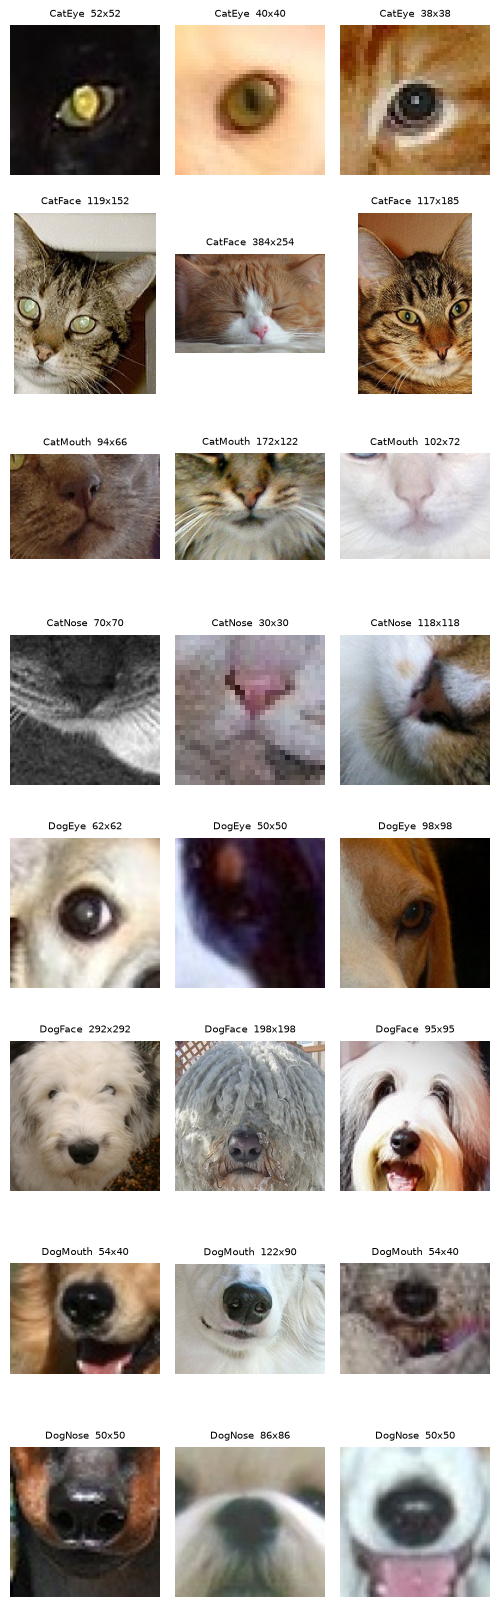

In [14]:
N = 3                                              # images shown per class (one row each)

# Only sample from images that opened correctly (error == '' means no decode error)
ok = train[train['error'] == '']

# For each class, randomly pick N images; random_state=SEED makes the same images appear every run.
# pd.concat stacks the 8 per-class selections into one table, in class order.
picks = pd.concat([ok[ok['class'] == c].sample(N, random_state=SEED) for c in classes])

# grid() lays them out N per row -> one row per class.
# The caption shows the class and the original pixel size (:.0f drops the decimal point,
# because width/height were read back from the CSV as floats).
grid(picks,
     lambda r: f"{r['class']}  {r.width:.0f}x{r.height:.0f}",
     n_cols=N,
     fname='samples_per_class.png')

### **5. Data Quality**

In [1]:
# Cut-offs used to FLAG images in the cells below. These are starting points only -
# look at the histograms and example grids, then set them where YOU judge images become
# unusable, and re-run 5b-5h. Note your chosen values and reasons in the report.
MIN_SIDE     = 32      # px: shorter side below this -> flagged as very small
DARK         = 25      # mean greyscale brightness below this (0-255 scale) -> very dark
BRIGHT       = 230     # mean greyscale brightness above this -> very bright / washed out
LOW_CONTRAST = 15      # greyscale standard deviation below this -> very flat image
BLUR_PCT     = 1.0     # the blurriest BLUR_PCT % of training images (by sharpness) are flagged

5a. Unreadable Files

In [11]:
# Cell 0b stored the exception text in 'error' for any file that failed to open or fully decode.
# Empty string = fine, so anything non-empty is a corrupted/unreadable file.
bad = stats[stats['error'] != '']
print('unreadable files:', len(bad))
display(bad[['split', 'image_id', 'error']])     # which files, and why they failed (empty table if none)

unreadable files: 0


,split,image_id,error


5b. Inconsistent Image Size and Aspect Ratios

split                  test      train
width      count    29443.0    63660.0
           mean       113.5      113.1
           std        100.7       98.5
           min          8.0        4.0
           25%         53.0       54.0
           50%         82.0       84.0
           75%        140.0      138.0
           max       1832.0     2219.0
height     count    29443.0    63660.0
           mean       109.7      109.7
           std        103.7      101.9
           min          9.0        4.0
           25%         50.0       50.0
           50%         80.0       80.0
           75%        128.0      130.0
           max       1978.0     2219.0
file_bytes count    29443.0    63660.0
           mean     10942.7    10864.8
           std      26538.9    24634.9
           min        693.0      660.0
           25%       2187.5     2209.0
           50%       4211.0     4333.5
           75%       9676.0     9864.0
           max    1204180.0  1262673.0

,width,height
class,,
CatEye,68,68
CatFace,182,215
CatMouth,114,80
CatNose,68,68
DogEye,62,62
DogFace,155,155
DogMouth,104,77
DogNose,62,62


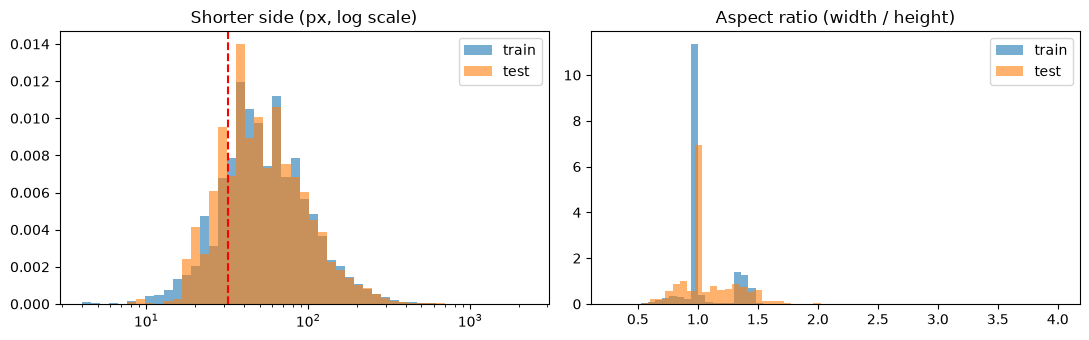

train images with shorter side < 32px: 4130 (6.49%)


class
CatEye      1459
DogEye       862
CatNose      731
CatMouth     484
DogNose      431
DogMouth     149
CatFace       14
Name: count, dtype: int64

test images with shorter side < 32px: 2422


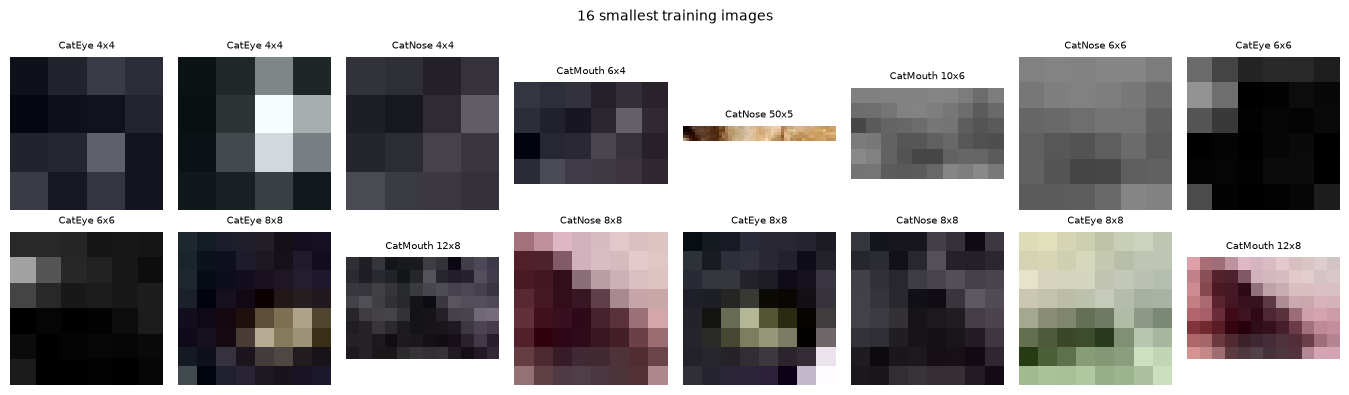

In [12]:
# Summary statistics of size per split. .describe() gives count/mean/std/min/quartiles/max;
# .T transposes so each property is a row.
display(stats.groupby('split')[['width', 'height', 'file_bytes']].describe().T.round(1))

# Median width/height for each class (median is less affected by a few huge images than the mean)
display(train.groupby('class')[['width', 'height']].median().astype(int))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
# Log-spaced bins: sizes range from tens to hundreds of pixels, so even bins on a log scale show both ends
bins = np.logspace(np.log10(max(1, stats.min_side.min())), np.log10(stats.min_side.max()), 50)
for s, d in (('train', train), ('test', test)):
    ax[0].hist(d.min_side, bins=bins, alpha=.6, density=True, label=s)        # shorter side of each image
    ax[1].hist(d.aspect.clip(0.25, 4), bins=60, alpha=.6, density=True, label=s)  # clip extreme ratios for readability
ax[0].set(xscale='log', title='Shorter side (px, log scale)')
ax[0].axvline(MIN_SIDE, c='r', ls='--')            # red dashed line = your MIN_SIDE threshold
ax[1].set(title='Aspect ratio (width / height)')
for a in ax: a.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'image_sizes.png', dpi=150); plt.show()

# How many images fall under the threshold, and in which classes
small = train[train.min_side < MIN_SIDE]
print(f'train images with shorter side < {MIN_SIDE}px: {len(small)} ({100*len(small)/len(train):.2f}%)')
display(small['class'].value_counts())
print(f'test images with shorter side < {MIN_SIDE}px:', (test.min_side < MIN_SIDE).sum())

# Look at the 16 smallest images to judge whether they are still recognisable
grid(train.nsmallest(16, 'min_side'), lambda r: f"{r['class']} {r.width:.0f}x{r.height:.0f}",
     fname='smallest_images.png', suptitle='16 smallest training images')

5c. Color/greyscale

mode,RGB
split,
test,29443
train,63660


images with no colour content (grey=True):


grey,False,True
split,,
test,28264,1179
train,61050,2610


class
CatEye      791
CatNose     436
DogEye      430
CatMouth    415
CatFace     283
DogNose     129
DogMouth     78
DogFace      48
Name: count, dtype: int64

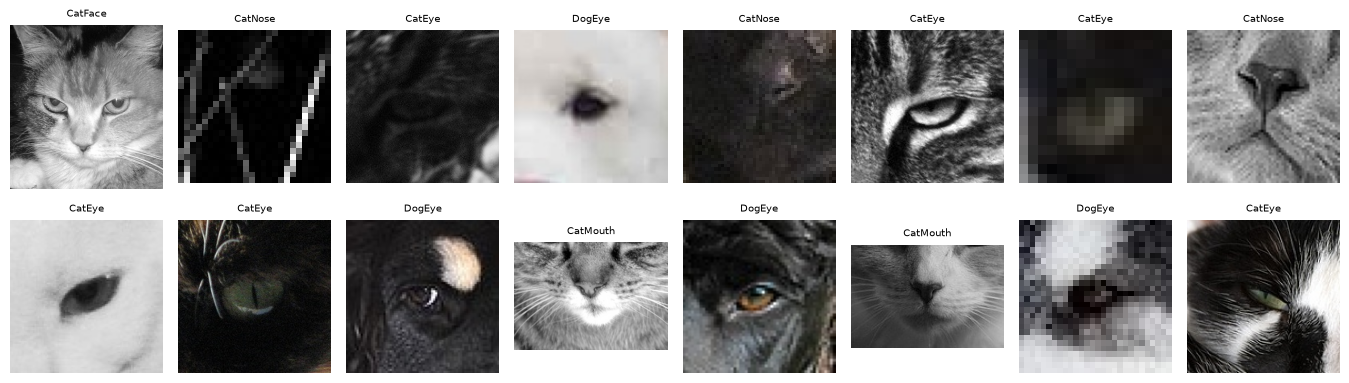

In [13]:
# 'mode' is how the file is STORED (RGB = colour, L = greyscale, ...), counted per split
display(pd.crosstab(stats['split'], stats['mode']))

# 'grey' (from Cell 0b) catches images with no colour content even if stored as RGB
print('images with no colour content (grey=True):')
display(pd.crosstab(stats['split'], stats['grey']))
display(train[train.grey]['class'].value_counts())     # which classes the greyscale images belong to

# Show up to 16 random greyscale examples (only if there are any)
g = train[train.grey]
if len(g):
    grid(g.sample(min(16, len(g)), random_state=SEED), lambda r: r['class'], fname='greyscale_examples.png')

5d. Unsuitable Contrasts

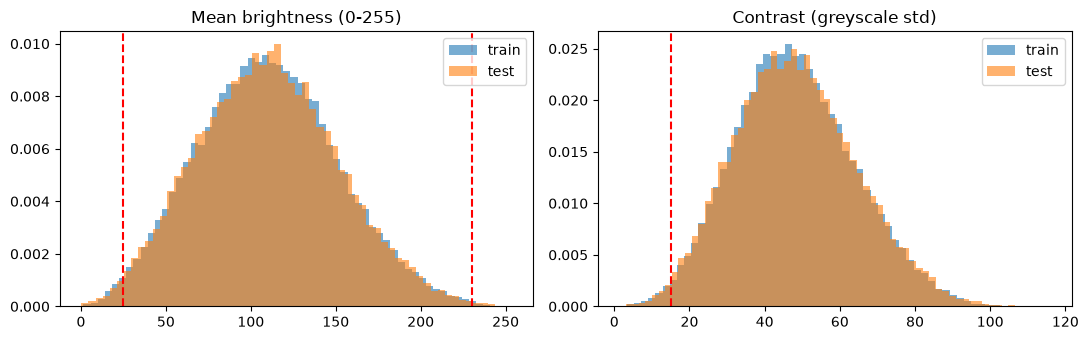

very dark    :   689 train images (1.08%)
very bright  :    89 train images (0.14%)
low contrast :   691 train images (1.09%)


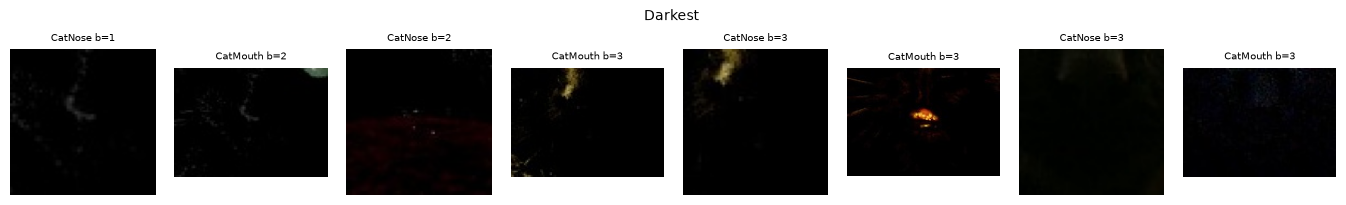

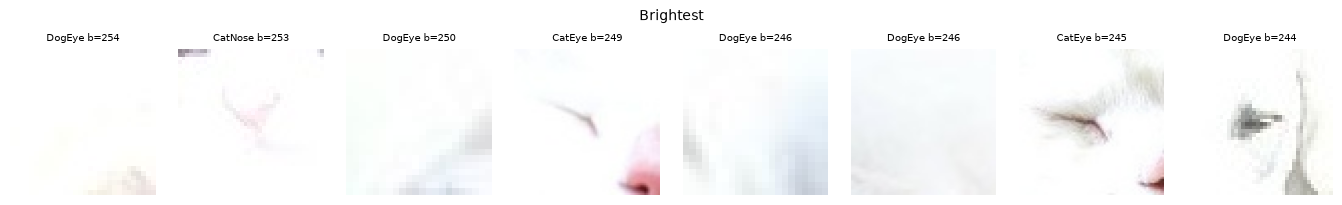

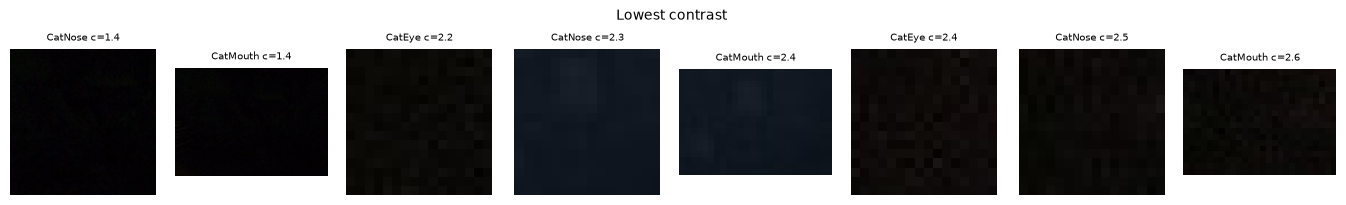

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for s, d in (('train', train), ('test', test)):
    ax[0].hist(d.brightness, bins=60, alpha=.6, density=True, label=s)   # mean pixel intensity per image
    ax[1].hist(d.contrast, bins=60, alpha=.6, density=True, label=s)     # spread of intensities per image
ax[0].set(title='Mean brightness (0-255)')
ax[0].axvline(DARK, c='r', ls='--'); ax[0].axvline(BRIGHT, c='r', ls='--')   # dark / bright thresholds
ax[1].set(title='Contrast (greyscale std)')
ax[1].axvline(LOW_CONTRAST, c='r', ls='--')                                   # low-contrast threshold
for a in ax: a.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'brightness_contrast.png', dpi=150); plt.show()

# Count images beyond each threshold. A boolean mask's .sum() = number of True values, .mean() = fraction True
for name, mask in [('very dark',    train.brightness < DARK),
                   ('very bright',  train.brightness > BRIGHT),
                   ('low contrast', train.contrast < LOW_CONTRAST)]:
    print(f'{name:13s}: {mask.sum():5d} train images ({100*mask.mean():.2f}%)')

# The most extreme examples of each, so you can judge them visually
grid(train.nsmallest(8, 'brightness'), lambda r: f"{r['class']} b={r.brightness:.0f}", suptitle='Darkest',         fname='darkest.png')
grid(train.nlargest(8, 'brightness'),  lambda r: f"{r['class']} b={r.brightness:.0f}", suptitle='Brightest',       fname='brightest.png')
grid(train.nsmallest(8, 'contrast'),   lambda r: f"{r['class']} c={r.contrast:.1f}",   suptitle='Lowest contrast', fname='low_contrast.png')

5e. Blurry Images

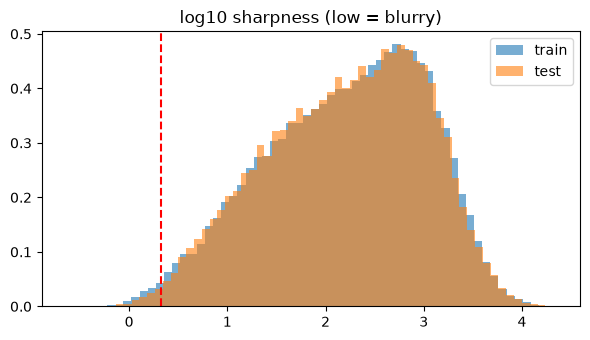

bottom 1.0% sharpness cut-off = 2.1 -> 637 train images


class
DogEye      195
CatEye      186
CatNose     162
DogNose      61
CatMouth     33
Name: count, dtype: int64

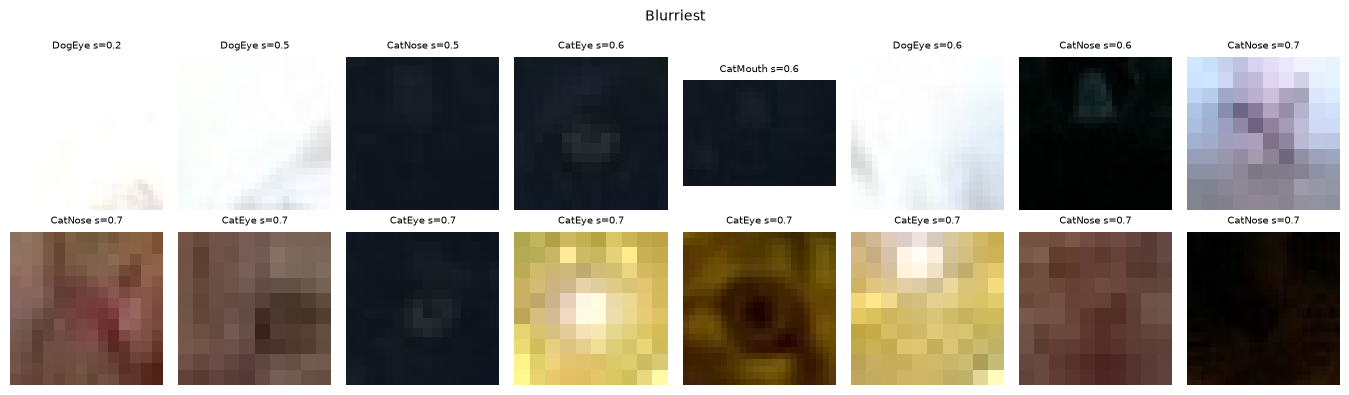

In [15]:
# Sharpness = variance of the Laplacian (Cell 0b). There's no universal "blurry" value, so the cut-off is
# a percentile: the score below which the blurriest BLUR_PCT % of training images fall.
# nanpercentile ignores unreadable images (NaN).
blur_cut = np.nanpercentile(train.sharpness, BLUR_PCT)

fig, ax = plt.subplots(figsize=(6, 3.5))
for s, d in (('train', train), ('test', test)):
    # Sharpness values span several orders of magnitude, so plot log10. +1e-3 avoids log10(0).
    ax.hist(np.log10(d.sharpness + 1e-3), bins=60, alpha=.6, density=True, label=s)
ax.axvline(np.log10(blur_cut + 1e-3), c='r', ls='--')     # cut-off line
ax.set(title='log10 sharpness (low = blurry)'); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'sharpness.png', dpi=150); plt.show()

blurry = train[train.sharpness <= blur_cut]
print(f'bottom {BLUR_PCT}% sharpness cut-off = {blur_cut:.1f} -> {len(blurry)} train images')
display(blurry['class'].value_counts())

# The 16 blurriest images
grid(train.nsmallest(16, 'sharpness'), lambda r: f"{r['class']} s={r.sharpness:.1f}", suptitle='Blurriest', fname='blurriest.png')

5f. Duplicate Images

[md5] train images in duplicate groups: 30  | groups: 15  | extra copies: 15  | groups with conflicting labels: 0
[md5] test images that also appear in train: 0  | duplicates within test: 62

[phash] train images in duplicate groups: 81  | groups: 40  | extra copies: 41  | groups with conflicting labels: 0
[phash] test images that also appear in train: 2  | duplicates within test: 68



,groups
class,
DogEye / DogEye,16
CatEye / CatEye,8
DogFace / DogFace,5
CatFace / CatFace,4
CatNose / CatNose,2
DogMouth / DogMouth,2
CatMouth / CatMouth,1
CatFace / CatFace / CatFace,1
DogNose / DogNose,1


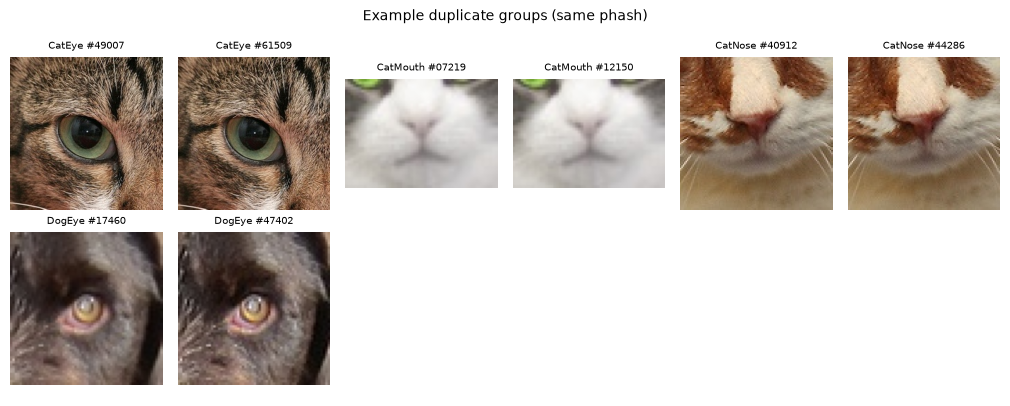

In [16]:
# Two kinds of duplicate (both hashes computed in Cell 0b):
#   md5   - fingerprint of the exact file bytes  -> byte-identical copies
#   phash - perceptual hash of the picture       -> visually identical, even if re-saved/resized
# Train-test overlap is COUNTED ONLY as a leakage check - it is never used to label test images.

def dup_summary(df, key):
    """Return (rows that share `key` with at least one other row, per-group summary)."""
    df = df[df[key].notna()]                                  # unreadable files have no hash - skip them
    d = df[df.duplicated(key, keep=False)]                    # keep=False marks EVERY member of a duplicate group
    groups = d.groupby(key)['class'].agg(['size', 'nunique']) # size = copies in group, nunique = distinct labels
    return d, groups

for key in ('md5', 'phash'):
    d, groups = dup_summary(train, key)
    print(f'[{key}] train images in duplicate groups: {len(d)}  | groups: {len(groups)}  '
          f'| extra copies: {len(d) - len(groups)}  '                    # copies beyond the first in each group
          f'| groups with conflicting labels: {(groups["nunique"] > 1).sum()}')   # same image, different labels
    print(f'[{key}] test images that also appear in train: {test[key].isin(train[key]).sum()}  '
          f'| duplicates within test: {test[key].duplicated().sum()}\n')

# Which label combinations the phash duplicate groups contain (e.g. 'CatEye / CatEye' or 'CatEye / DogEye')
d, groups = dup_summary(train, 'phash')       # phash results kept in d/groups for the next lines AND Cell 5h
display(d.groupby('phash')['class'].apply(lambda s: ' / '.join(sorted(s)))
          .value_counts().head(15).to_frame('groups'))

# Show example groups: up to 4 with conflicting labels first, then up to 4 with matching labels
conf = groups[groups['nunique'] > 1].index[:4].tolist()
same = groups[groups['nunique'] == 1].index[:4].tolist()
ex = d[d.phash.isin(conf + same)].sort_values(['phash', 'image_id'])   # sort so group members sit together
if len(ex):
    grid(ex.head(24), lambda r: f"{r['class']} #{r.image_id}", n_cols=6,
         fname='duplicate_examples.png', suptitle='Example duplicate groups (same phash)')

5g. Unclear Class Boundries

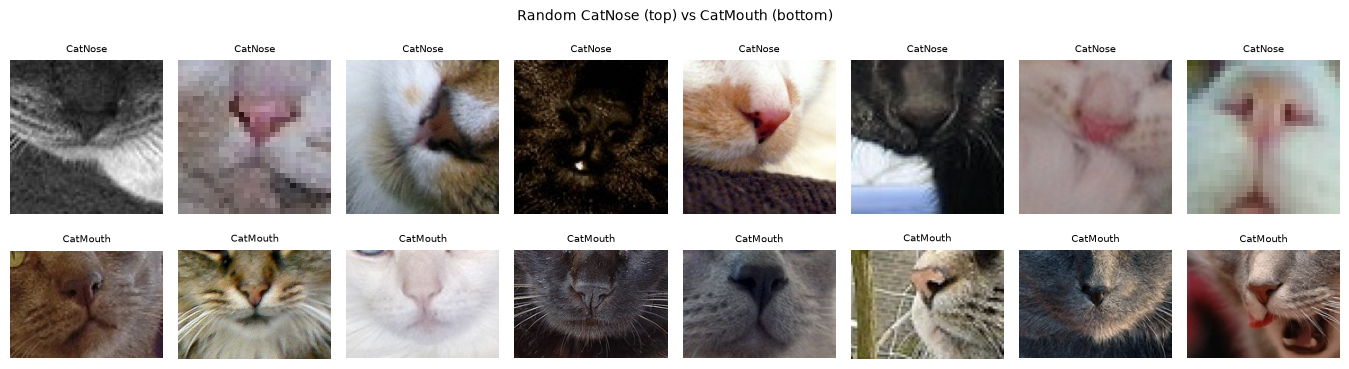

In [17]:
# Visual side-by-side of two classes to examine how distinguishable they are.
# Pick any pair - e.g. ones that look similar, or ones the confusion matrix mixes up.
CLASS_A, CLASS_B = 'CatNose', 'CatMouth'

ok = train[train['error'] == '']                                     # readable images only
pair = pd.concat([ok[ok['class'] == c].sample(8, random_state=SEED) for c in (CLASS_A, CLASS_B)])
grid(pair, lambda r: r['class'], n_cols=8,                           # 8 per row -> class A top, class B bottom
     fname=f'compare_{CLASS_A}_{CLASS_B}.png',
     suptitle=f'Random {CLASS_A} (top) vs {CLASS_B} (bottom)')

5h. Summary of Flagged Images

In [18]:
# One row per training image, one True/False column per issue, using the thresholds from Cell 5.
# Needs blur_cut (Cell 5e) and groups (Cell 5f) - run those first.
flags = pd.DataFrame({
    'image_id':      train.image_id,
    'class':         train['class'],
    'unreadable':    train['error'] != '',
    'too_small':     train.min_side < MIN_SIDE,
    'too_dark':      train.brightness < DARK,
    'too_bright':    train.brightness > BRIGHT,
    'low_contrast':  train.contrast < LOW_CONTRAST,
    'blurry':        train.sharpness <= blur_cut,
    # keep='first' -> the first image in each phash group is NOT flagged, every extra copy is
    'dup_extra':     train.phash.notna() & train.duplicated('phash', keep='first'),
    # True for every member of a phash group that contains more than one label
    'dup_conflict':  train.phash.map(groups['nunique']).fillna(1) > 1,
    'phash':         train.phash,          # kept so Task 2 can keep duplicate groups on one side of the split
})

flag_cols = [c for c in flags.columns if c not in ('image_id', 'class', 'phash')]
flags['any_flag'] = flags[flag_cols].any(axis=1)          # True if the image has at least one issue

# How many images each issue affects
summary = flags[flag_cols + ['any_flag']].sum().to_frame('train images')
summary['percent'] = (100 * summary['train images'] / len(flags)).round(2)
display(summary)

# Fraction of each class with at least one flag (shows whether issues concentrate in particular classes)
display(pd.crosstab(flags['class'], flags['any_flag'], normalize='index').round(3))

flags.to_csv('outputs/quality_flags.csv', index=False)    # input for the Task 2 cleaning options
print('saved outputs/quality_flags.csv')

,train images,percent
unreadable,0,0.00
too_small,4130,6.49
too_dark,689,1.08
too_bright,89,0.14
low_contrast,691,1.09
blurry,637,1.00
dup_extra,41,0.06
dup_conflict,0,0.00
any_flag,5271,8.28


any_flag,False,True
class,,
CatEye,0.863,0.137
CatFace,0.995,0.005
CatMouth,0.908,0.092
CatNose,0.863,0.137
DogEye,0.906,0.094
DogFace,0.998,0.002
DogMouth,0.972,0.028
DogNose,0.918,0.082


saved outputs/quality_flags.csv


# Task 2: Data Preprocessing and Pipeline Preparation

In [19]:
# ---- Imports ---------------------------------------------------------------
import torch                                   # PyTorch: tensors (multi-dimensional arrays) and deep learning
import timm                                    # library of pretrained image models (where EfficientNet comes from)
from torch.utils.data import DataLoader        # batches images together and feeds them to the model
from torchvision import transforms as T        # image preprocessing steps (resize, flip, normalise, ...)
from sklearn.model_selection import train_test_split, StratifiedGroupKFold   # the two splitting methods

# Import the preprocessing code directly from train.py, so the notebook demonstrates the
# EXACT same functions the training run uses - not a copy that could drift out of sync.
from Train import build_transforms, ImageDataset

# ---- Settings (must match the values used in train.py) --------------------------
IMG_SIZE = 160          # every image is resized to 160x160 pixels before entering the model (--img-size)
VAL_FRAC = 0.15         # 15% of the labelled images are held back for validation (--val-frac)

# ---- Normalisation statistics -----------------------------------------------
# The pretrained EfficientNet was trained on ImageNet photos that were normalised with specific
# per-channel mean and standard deviation values. Our images must be normalised the SAME way, or the
# pretrained weights receive inputs on a different scale from the one they learned on.
# timm stores these values in the model's config. pretrained=False builds the model with random
# weights, which is enough to read the config and avoids downloading the weights again.
cfg = timm.data.resolve_model_data_config(timm.create_model('efficientnet_b0', pretrained=False))
MEAN, STD = cfg['mean'], cfg['std']      # one value per colour channel (R, G, B)

# ---- Build the two transform pipelines ----------------------------------------
# build_transforms (from train.py) returns two pipelines:
#   train_tfm - random augmentation + resize + convert to tensor + normalise   (training images)
#   eval_tfm  - resize + convert to tensor + normalise, no randomness           (validation AND test images)
train_tfm, eval_tfm = build_transforms(IMG_SIZE, MEAN, STD)

# Print them so the notebook output documents exactly which steps are applied, in order
print('mean:', MEAN, ' std:', STD)
print('train transform:', train_tfm)
print('eval transform :', eval_tfm)

mean: (0.485, 0.456, 0.406)  std: (0.229, 0.224, 0.225)
train transform: Compose(
    RandomResizedCrop(size=(160, 160), scale=(0.7, 1.0), ratio=(0.8, 1.25), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)
eval transform : Compose(
    Resize(size=(160, 160), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


### **2.1 Resize Images**

original size: (36, 36) -> resized: (160, 160)
83.4% of training images have a shorter side below 160px (upscaled)


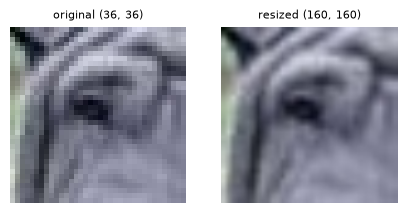

In [20]:
# Every image is resized to IMG_SIZE x IMG_SIZE, because the model needs a fixed input size
img = Image.open(IMG_DIR['train'] / f"{train.image_id.iloc[0]}.jpg").convert('RGB')
resized = T.Resize((IMG_SIZE, IMG_SIZE))(img)
print('original size:', img.size, '-> resized:', resized.size)
print(f'{(train.min_side < IMG_SIZE).mean():.1%} of training images have a shorter side below {IMG_SIZE}px (upscaled)')

fig, ax = plt.subplots(1, 2, figsize=(5, 2.5))
ax[0].imshow(img);     ax[0].set_title(f'original {img.size}', fontsize=8)
ax[1].imshow(resized); ax[1].set_title(f'resized {resized.size}', fontsize=8)
for a in ax: a.axis('off')
plt.show()

### **2.2 Normalise Pixel Values**

In [21]:
# Pixels go 0-255 -> 0-1 (ToTensor) -> centred on the ImageNet mean/std (Normalize)
x_raw  = np.asarray(resized, dtype=np.float32)      # as stored: 0-255
x_01   = T.ToTensor()(resized)                      # divided by 255: 0-1, shape (3, H, W)
x_norm = T.Normalize(MEAN, STD)(x_01)               # (x - mean) / std for each colour channel
for name, x in [('raw', x_raw), ('ToTensor', x_01), ('Normalize', x_norm)]:
    print(f'{name:9s}  min {float(x.min()):7.2f}   max {float(x.max()):7.2f}   mean {float(x.mean()):7.2f}')

raw        min    2.00   max  236.00   mean  125.27
ToTensor   min    0.01   max    0.93   mean    0.49
Normalize  min   -2.08   max    2.31   mean    0.19


### **2.3 Encode Class Labels**

In [22]:
# Class names -> integers 0-7, alphabetical (the same mapping train.py uses)
class_to_idx = {c: i for i, c in enumerate(classes)}
print(class_to_idx)
train['y'] = train['class'].map(class_to_idx)
display(train[['image_id', 'class', 'y']].head())

{'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}


,image_id,class,y
0,00001,DogEye,4
1,00002,DogMouth,6
2,00003,DogFace,5
3,00004,DogNose,7
4,00005,DogNose,7


### **2.4 Split into Training and Validation Sets**

In [23]:
# Stratified 85/15 split with the same seed as train.py -> every class keeps the same share in both sets
tr, va = train_test_split(train, test_size=VAL_FRAC, stratify=train['y'], random_state=SEED)
print(f'train: {len(tr)}   validation: {len(va)}   test (Kaggle): {len(test)}')
display(pd.DataFrame({'train %': tr['class'].value_counts(normalize=True) * 100,
                      'val %':   va['class'].value_counts(normalize=True) * 100}).round(2))

train: 54111   validation: 9549   test (Kaggle): 29443


,train %,val %
class,,
CatEye,21.81,21.81
CatFace,10.91,10.90
CatMouth,10.91,10.90
CatNose,10.91,10.90
DogEye,18.19,18.19
DogFace,9.09,9.10
DogMouth,9.10,9.09
DogNose,9.09,9.10


### **2.5 Training Data Augmentation**

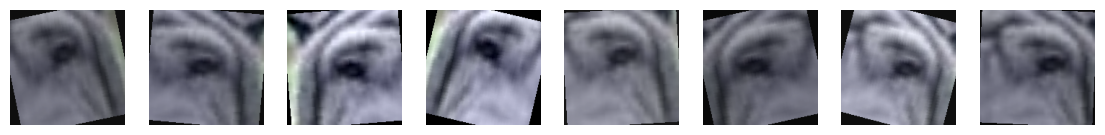

In [24]:
# 8 random versions of the same image, using the training transform's augmentation steps
aug = T.Compose(train_tfm.transforms[:-2])          # drop ToTensor + Normalize so the result can be displayed
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax in axes:
    ax.imshow(aug(img)); ax.axis('off')
plt.savefig(FIG_DIR / 'augmentation_examples.png', dpi=150); plt.show()

### **2.6 Dataset and Dataloader**

In [25]:
# ImageDataset loads each image from disk only when needed; DataLoader serves shuffled batches of 64
train_ds = ImageDataset(IMG_DIR['train'], tr['image_id'], tr['y'].values, train_tfm)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)
x, y = next(iter(train_dl))
print(f'{len(train_ds)} training images -> {len(train_dl)} batches of 64')
print('one batch: images', tuple(x.shape), '| labels', tuple(y.shape), y[:8].tolist())

54111 training images -> 846 batches of 64
one batch: images (64, 3, 160, 160) | labels (64,) [5, 6, 5, 2, 7, 0, 6, 6]


### **2.7 Consistent Pre-Processing for Train, Validation and Test**

In [26]:
# Validation and test both use eval_tfm (fixed steps); only training images get random augmentation
test_img = Image.open(IMG_DIR['test'] / f"{test.image_id.iloc[0]}.jpg").convert('RGB')
print('eval_tfm gives the same result twice :', torch.equal(eval_tfm(img), eval_tfm(img)))
print('train_tfm gives the same result twice:', torch.equal(train_tfm(img), train_tfm(img)))
print('validation tensor:', tuple(eval_tfm(img).shape), '| test tensor:', tuple(eval_tfm(test_img).shape))

eval_tfm gives the same result twice : True
train_tfm gives the same result twice: False
validation tensor: (3, 160, 160) | test tensor: (3, 160, 160)


### **2.8 Data Leakage Checks**

In [27]:
print('images in both train and val         :', len(set(tr.image_id) & set(va.image_id)))
print('duplicate groups in both (stratified):', len(set(tr.phash) & set(va.phash)))

# The same split with duplicate groups kept together (train.py --group-split)
folds = StratifiedGroupKFold(n_splits=round(1 / VAL_FRAC), shuffle=True, random_state=SEED)
tr_i, va_i = next(folds.split(train, train['y'], groups=train['phash']))
print('duplicate groups in both (group split):', len(set(train.phash.iloc[tr_i]) & set(train.phash.iloc[va_i])))

print('test images with a label             :', test['class'].notna().sum())
print('normalisation values (fixed, from ImageNet):', MEAN, STD)

images in both train and val         : 0
duplicate groups in both (stratified): 11
duplicate groups in both (group split): 0
test images with a label             : 0
normalisation values (fixed, from ImageNet): (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)


# Task 3: Model Selection and Pipeline Development

### **3.1 Model Architecture**

In [28]:
# Build the same model train.py uses (random weights are enough to inspect the structure)
model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=len(classes))
print(f'parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M')

for name, part in model.named_children():           # the main components, in order
    print(f'{name:12s} {type(part).__name__}')
print('MBConv blocks per stage:', [len(stage) for stage in model.blocks])

parameters: 4.0M
conv_stem    Conv2d
bn1          BatchNormAct2d
blocks       Sequential
conv_head    Conv2d
bn2          BatchNormAct2d
global_pool  SelectAdaptivePool2d
classifier   Linear
MBConv blocks per stage: [1, 2, 2, 3, 3, 4, 1]


### **3.2 Input, Output Layer and Activation Functions**

In [29]:
model.eval()
x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)            # one dummy image: 3 channels x 160 x 160
logits = model(x)                                    # raw class scores
probs = logits.softmax(dim=1)                        # softmax turns scores into probabilities

print('input :', tuple(x.shape), '-> output:', tuple(logits.shape), f'({len(classes)} classes)')
print('output layer:', model.classifier)
print('activations inside the network:',
      sorted({type(m).__name__ for m in model.modules() if isinstance(m, (torch.nn.SiLU, torch.nn.Sigmoid, torch.nn.ReLU))}))
print('softmax probabilities sum to:', round(probs.sum().item(), 4))

input : (1, 3, 160, 160) -> output: (1, 8) (8 classes)
output layer: Linear(in_features=1280, out_features=8, bias=True)
activations inside the network: ['SiLU', 'Sigmoid']
softmax probabilities sum to: 1.0


### **3.3 Training Settings**

In [30]:
# Settings used for a run, read from the config.json that train.py saves with every run
import json
RUN = 'effb0_160'
cfg_run = json.loads((Path('runs') / RUN / 'config.json').read_text())
display(pd.Series(cfg_run, name=RUN).to_frame())

# Fixed in train.py (not command-line options)
print('loss      : CrossEntropyLoss(label_smoothing =', cfg_run['label_smoothing'], ')')
print('optimiser : AdamW(lr =', cfg_run['lr'], ', weight_decay =', cfg_run['weight_decay'], ')')
print('scheduler : OneCycleLR (10% warm-up, then cosine decay), stepped every batch')
print('stopping  : early stopping after', cfg_run['patience'], 'epochs without validation-loss improvement')

,effb0_160
model,efficientnet_b0
img_size,160
epochs,12
batch_size,64
lr,0.0003
weight_decay,0.05
label_smoothing,0.1
val_frac,0.15
patience,3
workers,4


loss      : CrossEntropyLoss(label_smoothing = 0.1 )
optimiser : AdamW(lr = 0.0003 , weight_decay = 0.05 )
scheduler : OneCycleLR (10% warm-up, then cosine decay), stepped every batch
stopping  : early stopping after 3 epochs without validation-loss improvement


### **3.4 Kaggle Predictions**

In [31]:
# Check a run's submission.csv matches Kaggle's required format
sub    = pd.read_csv(Path('runs') / RUN / 'submission.csv')
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')

print('rows:', len(sub), '(expected', len(sample), ') | columns:', list(sub.columns))
print('same IDs in same order as sample_submission:', sub['image_id'].equals(sample['image_id']))
print('all predictions are valid class names:', sub['class'].isin(classes).all())
display(sub.head())
display(sub['class'].value_counts().to_frame('predicted test images'))

rows: 29443 (expected 29443 ) | columns: ['image_id', 'class']
same IDs in same order as sample_submission: True
all predictions are valid class names: True


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogNose
3,4,DogFace
4,5,CatMouth


,predicted test images
class,
CatEye,6227
DogEye,5662
CatMouth,3390
CatFace,3115
DogMouth,2803
DogFace,2801
CatNose,2761
DogNose,2684


### **3. **

### **3. **

Initial Runs

In [ ]:
import sys
!"{sys.executable}" train.py --limit 2000 --epochs 2 --run-name smoke

In [ ]:
!"{sys.executable}" train.py --run-name effb0_160